# 03 · Implied default odds: what the price says will happen

**The question:** if we take each bond's spread at face value, how likely does the market think a default is? And how does that compare with what has *actually happened* to companies with the same rating?

This is the credit version of the "Bayesian priors" chart from the SpaceX post:
- The **rating** is the prior. S&P publishes how often companies with each rating have defaulted since 1981.
- The **bond price** is the market's posterior. It's what investors are willing to pay today, after reading the same news we have.

**Short answer** (TRACE last trades, Nov 10, 2026; 5-year odds):
1. **Every bond's price implies far more defaults than history,** even Apple's (20–37× its rating's record). That gap is the price of illiquidity and risk, not a forecast, so the useful comparison is with bonds of the *same rating* (§1–3, `03_implied_default_odds.png`).
2. **Against their rating peers:**
   - Apple prices as *safer* than an average AA (0.5–0.9×).
   - Meta's long bonds price at ~3× an average AA.
   - The SPVs at ~4× an average A.
   - SpaceX at ~2× an average BBB (~20–21% odds).
   - CoreWeave at ~2.2–2.4× an average B (~60%), above even CCC's historical 46%.
3. **Recovery assumptions move the levels, but not the ranking** (§4).
4. **Since issue, SpaceX's implied odds rose most** (+9.3 points), then Meta 2056 (+4.9). Beignet and Sopaipilla haven't moved; Apple is flat to lower (§5).
5. **Timing** (§6, `03_default_timing.png`):
   - Meta's risk is priced as *late* (1% → 3.6% a year).
   - SpaceX's is flat from day one (~3.5–4% a year), not "safe now, risky later". Notebook 06 §5–6 explains why: on its spending plans it needs new money from about 2027.
   - CoreWeave is ~13.5–15% a year, with no view past 2032.
6. **What the yield buys** (§7, `03_what_the_yield_buys.png`): $100 in Treasuries becomes ~$125 by Oct 2031.
   - CoreWeave's ~15.1% yield turns it into ~$186 if CoreWeave pays in full, and into a loss if it defaults at any point before. It's worth it if you think the odds of full repayment are better than ~40–60%.
   - SpaceX's ~7.2% turns it into ~$139, only ~$14 more than Treasuries. That needs ~80–89% confidence of repayment.

The rating as prior, the price as posterior, in the spirit of the "Bayesian priors" chart from the SpaceX post:
- The **rating** is the prior. S&P publishes how often companies with each rating have defaulted since 1981.
- The **bond price** is the market's posterior: what investors pay today, after reading the same news we have.

**How this notebook gets there:**

| § | Question | Chart / table |
|---|---|---|
| 1 | How do you turn a spread into default odds? | (method) |
| 2 | What are the implied odds for every bond? | (table) |
| 3 | How do they compare with rating peers and with history? | `03_implied_default_odds.png` |
| 4 | How much does the recovery assumption matter? | (table) |
| 5 | Has the market grown more worried since each bond was sold? | (table) |
| 6 | *When* does the market expect the risk to arrive? | `03_default_timing.png` |
| 7 | What does a 15% (or 7%) yield actually buy you? | `03_what_the_yield_buys.png` |

**Inputs:** `data/spreads.csv` (from 02), `bonds.csv` (recovery assumptions and ratings), and S&P's 2024 default study (`data/sp/`). Run 01 and 02 first.

**Outputs:** `data/implied_pd.csv` and `data/forward_pd.csv` (used by 05 and 06), `data/yield_buys.csv` (§7, used by `research.ipynb`), plus the three `charts/03_*.png`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from common import INK, INK2, MUTED, GRID, AXIS, SURFACE, BOND, source_note

CHARTS = Path('charts'); CHARTS.mkdir(exist_ok=True)
bonds = pd.read_csv('bonds.csv', parse_dates=['maturity']).set_index('bond_id')
spreads = pd.read_csv('data/spreads.csv', parse_dates=['as_of'])
sp_hist = pd.read_csv('data/sp/cumulative_default_rates_1981_2024.csv', comment='#', index_col='rating') / 100
pd.options.display.float_format = '{:,.2f}'.format

## 1 · The credit triangle

A lender who expects to lose money on defaults has to charge for it. If a bond has probability **PD** of defaulting in a given year, and in a default you get back a fraction **R** of your money (the *recovery rate*), your expected loss per year is PD × (1 − R). Charging exactly that as extra yield gives:

$$\text{spread} \approx PD \times (1 - R) \quad\Longrightarrow\quad PD \approx \frac{\text{spread}}{1 - R}$$

Example: a 300bp (3%) spread with 40% recovery implies 3% ÷ 0.6 = **5% chance of default per year**.

**Over several years**, the bond has to survive every year. If the annual odds are PD, the chance of surviving T years is (1 − PD)^T, so:

$$\text{cumulative PD over } T \text{ years} = 1 - (1 - PD)^T$$

**Recovery matters a lot.** The same spread with 60% recovery implies 50% *more* defaults than with 40% recovery, since each default costs less. Our assumptions come from `bonds.csv` → `assumed_recovery`:

| Claim | R | Why |
|---|---|---|
| Senior unsecured (Apple, Alphabet, Meta, SpaceX, CoreWeave notes) | 40% | Long-run average for senior unsecured bonds |
| Beignet / Sopaipilla (SPV, secured by a data center leased to Meta) | 60% | A building plus Meta's capped residual value guarantee. But the guarantee only pays in specific cases (see notes) |

**What the formula leaves out.** It assumes the *whole* spread is pay for expected defaults. In reality the spread also pays for illiquidity (how hard the bond is to sell), uncertainty, and investors' dislike of losses that cluster in recessions. So **these are upper bounds**, called "risk-neutral" probabilities in finance. That's why we don't just compare them with history. We also compare each bond with the average bond of its rating, which carries the same kinds of premium.

**Next:** apply this to every bond. §2.

In [2]:
def annual_pd(spread_bp, recovery):
    """Credit triangle: annual default probability implied by a spread (bp) and recovery (0-1)."""
    return np.minimum(spread_bp / 1e4 / (1 - recovery), 1.0)

def cum_pd(pd_annual, years):
    """Chance of at least one default within `years`, at a constant annual rate."""
    return 1 - (1 - pd_annual) ** years

assert abs(annual_pd(300, 0.4) - 0.05) < 1e-12      # the worked example above
assert abs(cum_pd(0.10, 2) - 0.19) < 1e-12            # 1 - 0.9^2

## 2 · What are the implied odds for every bond?

Inputs are each bond's latest TRACE trade (Nov 10, 2026) and its G-spread from notebook 02.

**Why a 5-year horizon?** "Odds of default before maturity" isn't comparable across bonds: a 30-year bond has more years to go wrong than a 4-year one. So the headline uses a fixed **5-year** window for every bond. The odds to maturity are in the table too.

Columns:
- `pd_1y`: implied chance of default in any one year.
- `pd_5y`: implied chance of default within 5 years.
- `pd_life`: implied chance of default before the bond matures.
- `bucket_pd_5y`: the same calculation on the **average spread of the bond's rating bucket** (ICE OAS, same day), at the senior unsecured recovery rate. It's what the market charges a typical company with this rating.
- `hist_5y`: how often companies with this exact rating (to the notch) actually defaulted within 5 years, 1981–2024 (S&P, table 26).
- `x_bucket`: this bond's odds ÷ the bucket's odds. Above 1 means the market sees *this* bond as riskier than its rating peers.
- `x_history`: this bond's odds ÷ history. Expect this to be well above 1 for everyone, because of the premiums described above.

In [3]:
H = 5
BUCKET_R = bonds.loc[bonds.seniority == 'senior unsecured', 'assumed_recovery'].mode()[0]  # typical bond in an ICE index

lat = spreads[spreads.kind == 'trade'].sort_values('as_of').groupby('bond_id').tail(1).copy()
b = bonds.loc[lat.bond_id]
lat['rating'] = b.rating_sp.str.split().str[0].values
lat['R'] = b.assumed_recovery.values
lat['pd_1y'] = annual_pd(lat.g_spread, lat.R)
lat['pd_5y'] = cum_pd(lat.pd_1y, H)
lat['pd_life'] = cum_pd(lat.pd_1y, lat.years)
lat['bucket_pd_5y'] = cum_pd(annual_pd(lat.bucket_oas, BUCKET_R), H)
lat['hist_5y'] = lat.rating.map(sp_hist[f'Y{H}'])
lat['x_bucket'] = lat.pd_5y / lat.bucket_pd_5y
lat['x_history'] = lat.pd_5y / lat.hist_5y

ORDER = ['Apple', 'Alphabet', 'Meta', 'Meta (SPV)', 'SpaceX', 'CoreWeave']
lat = (lat.assign(rank=lat.issuer.map(ORDER.index), mat=lat.bond_id.map(bonds.maturity))
          .sort_values(['rank', 'mat']).reset_index(drop=True))
lat.to_csv('data/implied_pd.csv', index=False)  # used by 05/06

show = lat[['issuer', 'bond_id', 'rating', 'years', 'g_spread', 'R', 'pd_1y', 'pd_5y', 'pd_life',
            'bucket_pd_5y', 'hist_5y', 'x_bucket', 'x_history']].copy()
pct = ['pd_1y', 'pd_5y', 'pd_life', 'bucket_pd_5y', 'hist_5y']
show[pct] = show[pct] * 100
show.style.format({c: '{:.1f}%' for c in pct} | {'years': '{:.1f}', 'g_spread': '{:.0f}bp', 'R': '{:.0%}',
                   'x_bucket': '{:.1f}×', 'x_history': '{:.0f}×'}).hide(axis='index')

issuer,bond_id,rating,years,g_spread,R,pd_1y,pd_5y,pd_life,bucket_pd_5y,hist_5y,x_bucket,x_history
Apple,AAPL_4.20_2030,AA+,3.5,31bp,40%,0.5%,2.6%,1.8%,5.5%,0.1%,0.5×,20×
Apple,AAPL_4.75_2035,AA+,8.5,39bp,40%,0.6%,3.2%,5.4%,5.5%,0.1%,0.6×,25×
Apple,AAPL_4.85_2053,AA+,26.5,58bp,40%,1.0%,4.8%,22.8%,5.5%,0.1%,0.9×,37×
Alphabet,GOOG_4.100_2031,AA+,4.3,69bp,40%,1.1%,5.6%,4.8%,5.5%,0.1%,1.0×,43×
Alphabet,GOOG_4.800_2036,AA+,9.3,89bp,40%,1.5%,7.2%,12.9%,5.5%,0.1%,1.3×,55×
Alphabet,GOOG_5.650_2056,AA+,29.3,121bp,40%,2.0%,9.7%,44.9%,5.5%,0.1%,1.8×,74×
Meta,META_4.55_2031,AA-,4.5,93bp,40%,1.5%,7.5%,6.8%,5.5%,0.3%,1.4×,28×
Meta,META_5.25_2036,AA-,9.5,121bp,40%,2.0%,9.7%,17.7%,5.5%,0.3%,1.8×,36×
Meta,META_6.30_2056,AA-,29.5,198bp,40%,3.3%,15.4%,62.8%,5.5%,0.3%,2.8×,57×
Meta,META_5.55_2064,AA-,37.8,215bp,40%,3.6%,16.7%,74.8%,5.5%,0.3%,3.1×,62×


**What this shows** (5-year implied odds, `pd_5y`):
- **Apple 3–5%; Alphabet 6–10%; Meta 7–17%,** rising with maturity in each case.
- **Beignet 23%, Sopaipilla 26%,** at 60% recovery.
- **SpaceX ~20–21%.**
- **CoreWeave ~58–61%.**
- **Against history:** even Apple's price implies 20–37× its rating's record. So read the `x_bucket` column, not `x_history`.

**Next:** the chart in §3 puts each bond next to its rating peers and next to history.

## 3 · How do they compare with rating peers and with history?

Three markers per bond, all for a 5-year window:
- **Blue dot:** what this bond's price implies.
- **Gray tick:** what the market charges the *average* bond with the same rating.
- **Hollow diamond:** what actually happened, historically, to companies with this rating.

The gap from diamond to tick is the premium the market charges *everyone* in that rating. The gap from tick to dot is what it charges *this bond specifically*. The x-axis is logarithmic: each gridline is a multiple.

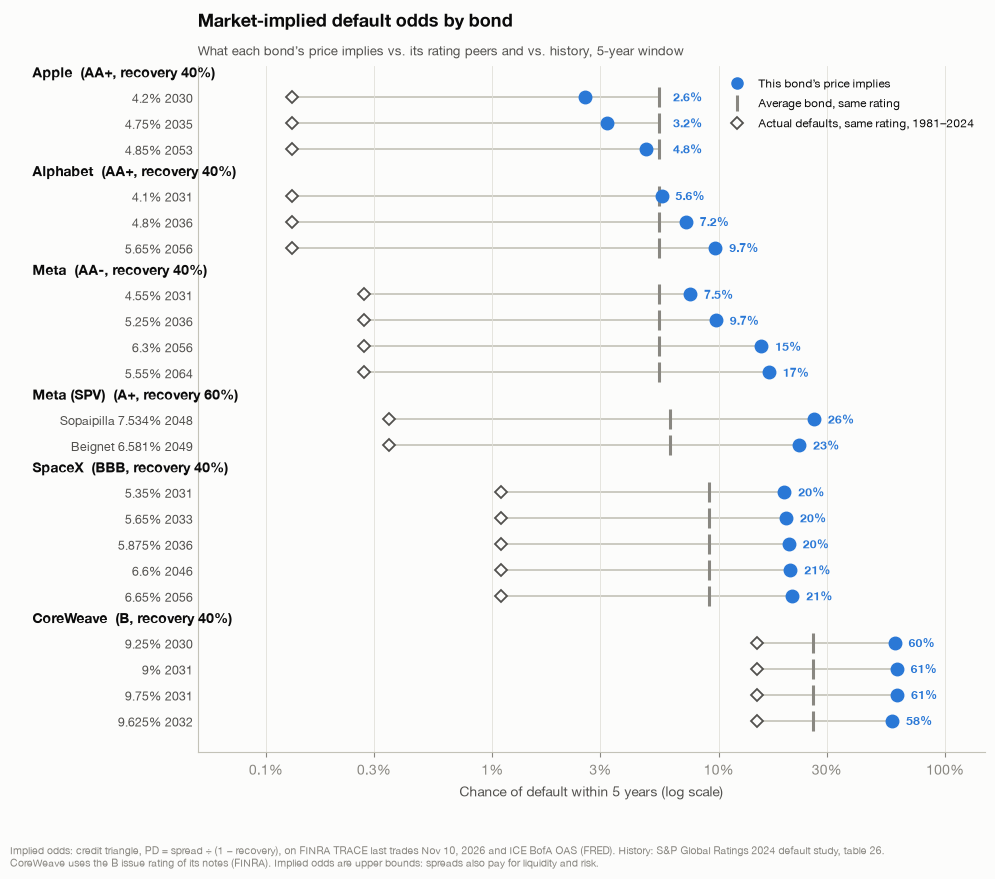

In [4]:
def short_label(bid):
    b = bonds.loc[bid]
    name = {'BEIGNET_6.581_2049': 'Beignet', 'SOPAIPILLA_2048': 'Sopaipilla'}.get(bid, '')
    return f'{name} {b.coupon:g}% {b.maturity:%Y}'.strip()

def fmt_pct(v):
    return f'{v:.1%}' if v < 0.1 else f'{v:.0%}'

ys, y, prev = [], 0, None
for iss in lat.issuer:
    if prev is not None and iss != prev: y += 0.8
    ys.append(y); y += 1; prev = iss
lat['y'] = ys

fig, ax = plt.subplots(figsize=(10, 8.5))
for r in lat.itertuples():
    pts = [v for v in (r.hist_5y, r.bucket_pd_5y, r.pd_5y) if pd.notna(v)]
    ax.plot([min(pts), max(pts)], [r.y, r.y], color=AXIS, lw=1.2, zorder=1)
    ax.plot(r.hist_5y, r.y, 'D', ms=6, mfc=SURFACE, mec=INK2, mew=1.3, zorder=2)
    if pd.notna(r.bucket_pd_5y):
        ax.plot(r.bucket_pd_5y, r.y, marker='|', ms=14, mew=2.2, color=MUTED, zorder=2)
    ax.plot(r.pd_5y, r.y, 'o', ms=9, mfc=BOND, mec=BOND, zorder=3)
    ax.annotate(f'{fmt_pct(r.pd_5y)}', (max(pts), r.y), xytext=(10, 0), textcoords='offset points',
                va='center', fontsize=8.5, color=BOND, fontweight='bold')

ax.set_xscale('log')
ax.set_xlim(0.0005, 1.5)
ticks = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0]
ax.xaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.1%}' if v < 0.01 else f'{v:.0%}'))
ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.set_yticks(lat.y, [short_label(b) for b in lat.bond_id], fontsize=9)
ax.invert_yaxis(); ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
for iss, grp in lat.groupby('issuer', sort=False):
    r0 = grp.iloc[0]
    ax.text(-0.21, grp.y.min() - 0.75, f'{iss}  ({r0.rating}, recovery {r0.R:.0%})', transform=ax.get_yaxis_transform(),
            fontweight='bold', fontsize=10, color=INK)
ax.set_xlabel(f'Chance of default within {H} years (log scale)')
ax.set_title('Market-implied default odds by bond', pad=28)
ax.text(0, 1.015, f'What each bond’s price implies vs. its rating peers and vs. history, {H}-year window',
        transform=ax.transAxes, fontsize=9.5, color=INK2)
ax.legend(handles=[
    Line2D([], [], marker='o', ls='', ms=8, mfc=BOND, mec=BOND, label='This bond’s price implies'),
    Line2D([], [], marker='|', ls='', ms=12, mew=2.2, color=MUTED, label='Average bond, same rating'),
    Line2D([], [], marker='D', ls='', ms=6, mfc=SURFACE, mec=INK2, mew=1.3, label='Actual defaults, same rating, 1981–2024'),
], loc='upper right', fontsize=8.5)
source_note(fig, f'Implied odds: credit triangle, PD = spread ÷ (1 − recovery), on FINRA TRACE last trades {lat.as_of.max():%b %-d, %Y} and ICE BofA OAS (FRED).\n'
                 'History: S&P Global Ratings 2024 default study, table 26. CoreWeave uses the B issue rating of its notes (FINRA). Implied odds are upper bounds: spreads also pay for liquidity and risk.')
fig.tight_layout(rect=(0.02, 0.035, 1, 1))
fig.savefig(CHARTS / '03_implied_default_odds.png', dpi=200)
plt.show()

**What this shows** (`charts/03_implied_default_odds.png`, above):
- **The diamond-to-tick gap** (history to rating average) is large for everyone. That's the premium the market charges *all* bonds of that rating.
- **The tick-to-dot gap** (rating average to this bond) is the bond-specific part:
  - Apple sits below its AA tick.
  - Alphabet and Meta are near their tick at 5 years, above it at 30.
  - The SPVs are ~4× their A tick; SpaceX ~2× its BBB tick.
  - CoreWeave is ~2.2–2.4× the B tick, beyond even CCC's historical 46%.

**Next:** all of this rests on the recovery assumption. §4 varies it.

## 4 · How much does the recovery assumption matter?

One bond per issuer, 5-year implied default odds across recovery assumptions. Read across a row: the price is fixed, and only our guess about recovery changes.

The last two columns give S&P's historical 5-year default rate for the bond's rating, and for CCC as a reference point.

In [5]:
REP = ['AAPL_4.75_2035', 'GOOG_4.800_2036', 'META_5.25_2036', 'SOPAIPILLA_2048', 'BEIGNET_6.581_2049',
       'SPCX_5.875_2036', 'CRWV_9.75_2031']
RS = [0.0, 0.2, 0.4, 0.6, 0.8]
L = lat.set_index('bond_id').loc[REP]
sens = pd.DataFrame({f'R = {r:.0%}': cum_pd(annual_pd(L.g_spread, r), H) for r in RS})
sens.insert(0, 'spread', L.g_spread)
sens[f'history ({H}y, own rating)'] = L.hist_5y
sens[f'history ({H}y, CCC/C)'] = sp_hist.loc['CCC/C', f'Y{H}']
cols = [c for c in sens if c != 'spread']
sens.style.format({c: '{:.1%}' for c in cols} | {'spread': '{:.0f}bp'})

,spread,R = 0%,R = 20%,R = 40%,R = 60%,R = 80%,"history (5y, own rating)","history (5y, CCC/C)"
bond_id,,,,,,,,
AAPL_4.75_2035,39bp,1.9%,2.4%,3.2%,4.8%,9.3%,0.1%,46.5%
GOOG_4.800_2036,89bp,4.3%,5.4%,7.2%,10.6%,20.3%,0.1%,46.5%
META_5.25_2036,121bp,5.9%,7.4%,9.7%,14.3%,26.9%,0.3%,46.5%
SOPAIPILLA_2048,238bp,11.3%,14.0%,18.3%,26.4%,46.9%,0.3%,46.5%
BEIGNET_6.581_2049,201bp,9.6%,11.9%,15.6%,22.7%,41.1%,0.3%,46.5%
SPCX_5.875_2036,268bp,12.7%,15.7%,20.4%,29.3%,51.3%,1.1%,46.5%
CRWV_9.75_2031,1041bp,42.3%,50.2%,61.4%,77.9%,97.5%,14.7%,46.5%


**What this shows:**
- **Levels move a lot:** at 0% vs. 80% recovery, CoreWeave's 5-year odds range 42–98%, and SpaceX's 13–51%.
- **The ranking never changes.**
- **CoreWeave stays near or above CCC history (46.5%) at any recovery above ~20%.** Its unsecured notes rank behind ~$25B of secured debt, so low recovery is plausible. That *lowers* its implied odds, but not below B history (14.7%).

**Next:** levels aside, has anything changed since each bond was sold? §5.

## 5 · Has the market grown more worried since each bond was sold?

The same 5-year implied odds, computed from the spread when each bond was sold and from the latest trade. This is the cleanest "has it gotten worse?" measure, because it compares the bond with itself. (It still includes moves in the whole credit market. Notebook 02's excess-spread change strips those out.)

In [6]:
iss = spreads[spreads.kind == 'issue'].groupby('bond_id').head(1).set_index('bond_id')
common = iss.index.intersection(lat.bond_id)
now = lat.set_index('bond_id').loc[common]
R = bonds.loc[common, 'assumed_recovery']
then_pd = cum_pd(annual_pd(iss.loc[common, 'g_spread'], R), H)
pd.DataFrame({'issued': iss.loc[common, 'as_of'].dt.date, 'spread then': iss.loc[common, 'g_spread'],
              'spread now': now.g_spread, f'{H}y odds then': then_pd, f'{H}y odds now': now.pd_5y,
              'change (pts)': (now.pd_5y - then_pd) * 100}
            ).style.format({'spread then': '{:.0f}bp', 'spread now': '{:.0f}bp', f'{H}y odds then': '{:.1%}',
                            f'{H}y odds now': '{:.1%}', 'change (pts)': '{:+.1f}'})

,issued,spread then,spread now,5y odds then,5y odds now,change (pts)
bond_id,,,,,,
BEIGNET_6.581_2049,2025-10-16,201bp,201bp,22.8%,22.7%,-0.1
GOOG_4.100_2031,2026-02-10,43bp,69bp,3.5%,5.6%,+2.1
GOOG_4.800_2036,2026-02-10,63bp,89bp,5.1%,7.2%,+2.0
GOOG_5.650_2056,2026-02-10,83bp,121bp,6.7%,9.7%,+2.9
META_4.55_2031,2026-04-30,53bp,93bp,4.3%,7.5%,+3.1
META_5.25_2036,2026-04-30,90bp,121bp,7.3%,9.7%,+2.4
META_6.30_2056,2026-04-30,132bp,198bp,10.5%,15.4%,+4.9
SPCX_5.875_2036,2026-06-23,140bp,268bp,11.1%,20.4%,+9.3
SOPAIPILLA_2048,2026-07-27,239bp,238bp,26.5%,26.4%,-0.1


**What this shows** (change in 5-year implied odds, percentage points):
- **SpaceX 2036: +9.3** (11% → 20%). The biggest move.
- **Meta 2056: +4.9.** Alphabet 2056: +2.9. The long ends of the AI spenders.
- **Beignet −0.1, Sopaipilla −0.1.** The SPVs haven't moved since issue.
- **Apple: flat to −4,** as safe as or safer than when it was sold.

**Next:** §1–5 assume the risk is the same every year. Different issuers have very different timelines, so §6 reads the timeline from the prices.

## 6 · When does the market expect the risk to arrive?

Sections 2–5 assume default risk is **the same every year**. It isn't. Each issuer has its own timeline:

- **CoreWeave**: the risk is near-term. It's burning cash, depends on a few customers, and has a wall of debt to refinance.
- **SpaceX**: ~$52B of net cash at Sep 30 ($89.9B cash and securities vs. $38.0B debt), and no bond matures before July 2031. A default in the next two years is hard to picture. But 9-month free cash flow was about −$35B. If that pace holds, the cushion is gone in a year or two, and the risk piles up *later*.
- **Meta / Alphabet**: hugely profitable today. The question is whether $100B+ a year of capex pays off over the next decade, which is also a later risk.
- **Apple**: could stop doing anything new for five years and still pay every bond. That's what makes it the control.

**Reading the timeline from prices.** An issuer with bonds maturing at several dates gives us several "average risk to date" readings. If the 5-year bond implies 1% a year and the 10-year bond implies 2% a year on average, years 5–10 must carry about 3% a year, since (5 × 1% + 5 × 3%) ÷ 10 = 2%. This is called **bootstrapping forward default rates**. In symbols, each bond's spread gives a *cumulative* hazard:

$$\Lambda(T) = \frac{s(T) \cdot T}{1 - R}$$

The default rate for the period between two maturities is the extra hazard per extra year:

$$\lambda_{T_1 \to T_2} = \frac{\Lambda(T_2) - \Lambda(T_1)}{T_2 - T_1}$$

Shown as annual odds: $1 - e^{-\lambda}$.

**Using Apple as the control.** Even Apple pays more for longer bonds: 31bp for 2030, 39bp for 2035, 58bp for 2053. That isn't default risk. It's what investors charge for tying money up longer (plus liquidity and duration demand at the long end). If we bootstrapped raw spreads, every issuer would look like its risk rises over time, just because of this term premium. So we subtract Apple's spread at the same maturity first (interpolated between its three bonds and held flat beyond 2053), and bootstrap what's left. What remains is "risk Apple doesn't have."

**Limits, stated up front:**
- **We can't see inside the shortest bond.** SpaceX's shortest note matures in 4.7 years, so the market gives us one *average* for years 0–4.7. It can't say whether that risk falls in years 1–2 or 3–4.
- **Close maturities amplify noise.** A one-point mistake in a single last-trade print moves a forward rate a lot when two bonds mature only months apart. So we only use bonds at least 2 years apart (CoreWeave's four notes, 3.6–5.7 years out, collapse to two periods).
- **Meta's SPVs have one maturity each** (~22 years), so they have no timeline of their own.
- **The spread isn't only default.** For an investment-grade bond it also pays for the risk of a **downgrade**: if SpaceX fell to junk, many holders would be forced to sell at a loss even with no default. That risk can bite early.

In [7]:
MIN_GAP = 2.0                                       # years between bonds used for bootstrapping
apple = lat[lat.issuer == 'Apple'].sort_values('years')
apple_curve = lambda t: np.interp(t, apple.years, apple.g_spread)   # flat beyond the ends

def forward_curve(g, base=apple_curve):
    """Bootstrap forward annual default rates from one issuer's bonds, net of a base (control) curve."""
    keep = []
    for r in g.sort_values('years').itertuples():
        if not keep or r.years - keep[-1].years >= MIN_GAP:
            keep.append(r)
    rows, t0, cum0 = [], 0.0, 0.0
    for r in keep:
        net = r.g_spread - base(r.years)
        cum = net / 1e4 * r.years / (1 - r.R)
        lam = (cum - cum0) / (r.years - t0)
        rows.append({'issuer': r.issuer, 'through bond': r.bond_id, 'from (yrs)': t0, 'to (yrs)': r.years,
                     'spread': r.g_spread, 'Apple at same maturity': base(r.years), 'net of Apple': net,
                     'forward hazard': lam, 'annual odds': 1 - np.exp(-lam)})
        t0, cum0 = r.years, cum
    return pd.DataFrame(rows)

# check: a flat 300bp curve with R=40% must give a flat 5%/yr hazard in every period
_flat = pd.DataFrame({'issuer': 'x', 'bond_id': ['a', 'b', 'c'], 'years': [5., 10., 30.], 'g_spread': 300., 'R': 0.4})
assert np.allclose(forward_curve(_flat, base=lambda t: 0.0)['forward hazard'], 0.05)

TIMED = ['Alphabet', 'Meta', 'SpaceX', 'CoreWeave']
fwd = pd.concat([forward_curve(lat[lat.issuer == i]) for i in TIMED], ignore_index=True)
fwd['negative?'] = fwd['forward hazard'] < 0
fwd.to_csv('data/forward_pd.csv', index=False)   # handoff to 06
fwd.style.format({'from (yrs)': '{:.1f}', 'to (yrs)': '{:.1f}', 'spread': '{:.0f}bp', 'Apple at same maturity': '{:.0f}bp',
                  'net of Apple': '{:.0f}bp', 'forward hazard': '{:.2%}', 'annual odds': '{:.1%}'}).hide(axis='index')

issuer,through bond,from (yrs),to (yrs),spread,Apple at same maturity,net of Apple,forward hazard,annual odds,negative?
Alphabet,GOOG_4.100_2031,0.0,4.3,69bp,32bp,36bp,0.61%,0.6%,False
Alphabet,GOOG_4.800_2036,4.3,9.3,89bp,40bp,49bp,0.99%,1.0%,False
Alphabet,GOOG_5.650_2056,9.3,29.3,121bp,58bp,63bp,1.15%,1.1%,False
Meta,META_4.55_2031,0.0,4.5,93bp,33bp,60bp,1.00%,1.0%,False
Meta,META_5.25_2036,4.5,9.5,121bp,40bp,82bp,1.68%,1.7%,False
Meta,META_6.30_2056,9.5,29.5,198bp,58bp,139bp,2.78%,2.7%,False
Meta,META_5.55_2064,29.5,37.8,215bp,58bp,157bp,3.64%,3.6%,False
SpaceX,SPCX_5.350_2031,0.0,4.7,255bp,33bp,222bp,3.70%,3.6%,False
SpaceX,SPCX_5.650_2033,4.7,6.7,260bp,36bp,224bp,3.81%,3.7%,False
SpaceX,SPCX_5.875_2036,6.7,9.7,268bp,40bp,228bp,3.95%,3.9%,False


/var/folders/wm/gm9z3b_j4cjb_n2bg_3ydpy80000gn/T/ipykernel_40892/448914872.py:2: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  yr0 = NOW.year + (NOW.dayofyear - 1) / 365.25


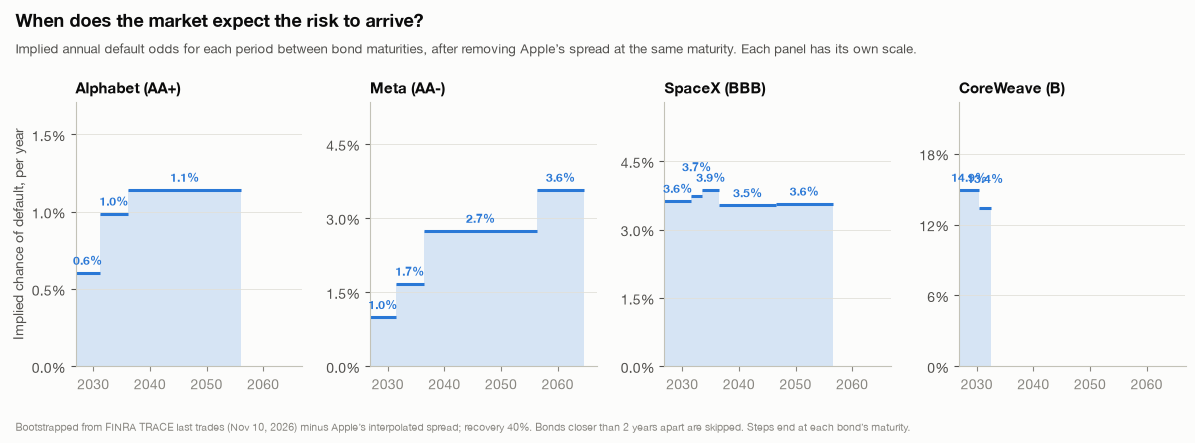

In [8]:
NOW = lat.as_of.max()
yr0 = NOW.year + (NOW.dayofyear - 1) / 365.25

fig, axes = plt.subplots(1, len(TIMED), figsize=(12, 4.2), sharex=True)
for ax, iss in zip(axes, TIMED):
    f = fwd[fwd.issuer == iss]
    r0 = lat[lat.issuer == iss].iloc[0]
    for i, (t0, t1, p) in enumerate(f[['from (yrs)', 'to (yrs)', 'annual odds']].itertuples(index=False, name=None)):
        a, b = yr0 + t0, yr0 + t1
        lift = 16 if (t1 - t0 < 3 and i % 2) else 4     # stagger labels on short steps
        ax.fill_between([a, b], 0, p, color=BOND, alpha=0.18, lw=0)
        ax.plot([a, b], [p, p], color=BOND, lw=2.2, solid_capstyle='butt')
        ax.annotate(f'{p:.1%}', ((a + b) / 2, p), xytext=(0, lift), textcoords='offset points',
                    ha='center', va='bottom', fontsize=8.5, color=BOND, fontweight='bold')
    ax.set_ylim(0, f['annual odds'].max() * 1.5)
    ax.set_title(f'{iss} ({r0.rating})', fontsize=11)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1, decimals=0 if f['annual odds'].max() > 0.05 else 1))
    ax.yaxis.set_major_locator(mticker.MaxNLocator(4))
    ax.grid(axis='x', visible=False)
axes[0].set_ylabel('Implied chance of default, per year')
axes[0].set_xlim(yr0, yr0 + 40)
axes[0].xaxis.set_major_locator(mticker.FixedLocator([2030, 2040, 2050, 2060]))
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'{v:.0f}'))
fig.suptitle('When does the market expect the risk to arrive?', x=0.01, ha='left', fontweight='bold', fontsize=13)
fig.text(0.01, 0.875, 'Implied annual default odds for each period between bond maturities, after removing Apple’s spread at the same maturity. '
         'Each panel has its own scale.', fontsize=9.5, color=INK2)
source_note(fig, f'Bootstrapped from FINRA TRACE last trades ({NOW:%b %-d, %Y}) minus Apple’s interpolated spread; recovery 40%. '
                 'Bonds closer than 2 years apart are skipped. Steps end at each bond’s maturity.')
fig.subplots_adjust(left=0.06, right=0.985, bottom=0.13, top=0.76, wspace=0.3)
fig.savefig(CHARTS / '03_default_timing.png', dpi=200)
plt.show()

**What this shows** (`charts/03_default_timing.png`, above). Flat steps mean the market charges the same every year. Rising steps mean it expects trouble later. Falling steps mean it sees the danger as near-term (or prices the bonds on recovery rather than yield, which is what distressed bonds do).

**What it says (Nov 10, 2026 prices; re-check after each refresh):**

- **Meta's risk is priced as long-dated.** About 1% a year through 2031, 1.7% to 2036, then **~2.7% a year for 2036–2056** and 3.6% after that. The market isn't worried about Meta paying its bills this decade. It's worried about what Meta looks like after a decade of $100B+ capex. Of all the curves, this one rises most steeply.
- **Alphabet has the same shape, at a third of the level.** It goes from 0.6% to 1.2% and then stays flat.
- **SpaceX is flat from day one, at ~3.5–4% a year.** That's *not* the "safe now, risky later" shape its balance sheet suggests. Two readings, and the prices can't tell them apart:
  1. **The danger really is inside the first window.** The shortest bond matures in 4.7 years. If the burn continues, net cash runs out in roughly 1–2 years, and the July 2031 maturity is the first real test. A default in years 3–5 sits inside that first step, so "no default for two years" and "3.5% a year over five years" don't conflict.
  2. **The near-term spread isn't about default.** It pays for things a net-cash company can still lose on: a downgrade to junk that forces holders to sell, the ~$40B of secured GPU debt that could rank ahead of these notes (the indenture's purchase-money lien carve-out allows it), and the illiquidity of a new 144A issuer.

  **Notebook 06 resolves much of this** (§5–8):
  - On consensus numbers, SpaceX needs new money by Dec 2027, so the funding question starts about a year out.
  - The ~$40B of GPU financing turned out to be an Apollo-owned finance lease (8-K, Oct 26). It ranks ahead of these notes on those GPUs.
  - The options market is also flat for SpaceX.
  - The stock implies ~1bp of default spread. So reading 2 is real too: much of the ~255bp isn't about the equity being wiped out.

  Either way, the market charges *no more* for 2036–2046 than for 2031–2033. That means it sees SpaceX as binary: if the spending pays off within about five years, it isn't riskier later. That's a bet on the next five years, not the next thirty.
- **CoreWeave: ~13.5–15% a year, roughly flat, and blind past 2032.** Its last bond matures in 2032, so the market gives no view beyond that. The curve is flat rather than falling, but with only two usable periods that tells us little. For distressed bonds, prices also start to converge toward expected recovery whatever the maturity, which makes yields less meaningful.
- **Apple subtraction matters.** Without it, every curve would rise just from the term premium. Apple's own spread climbs 27bp from 2030 to 2053.

## 7 · What does a 15% (or 7%) yield actually buy you?

**Why ask.** §1–6 talk in spreads (basis points) and implied odds. A buyer sees something simpler: a price and a yield. CoreWeave's 9.75% 2031 notes trade at 82.00¢ and yield **~15.1% a year**; SpaceX's 5.35% 2031 notes trade at 92.74¢ and yield **~7.2%**; a Treasury maturing in 2031 yields **~4.7%**. (A basis point, bp, is 0.01 percentage point, so 1,041bp is 10.41 points.) The yield is what you earn *if every payment arrives*. So: what do you end up with if it doesn't, and how confident do you have to be that it does?

These are the only two 5-year bonds in our set that pay much above Treasuries: Apple 4.9%, Alphabet 5.3%, Meta 5.6%. The Meta SPVs yield ~7.3–7.7% too, but they're ~15–22-year bonds, and most of that is the longer Treasury rate (§2; 07).

**Method, in plain language.** Put $100 into each bond today and follow the cash to Oct 2031 (when the CoreWeave notes mature):
- **You pay** the price plus the interest accrued since the last coupon.
- **You receive** a coupon every six months, and $100 per $100 of face value at maturity.
- **If it defaults** at some date, the coupons stop, and you receive the recovery rate R per $100 of face value then.
- **Everything you receive is reinvested in Treasuries** until Oct 2031, so every scenario ends on the same date and can be compared in dollars.
- The **Treasury benchmark** is $100 compounding at the 2031 Treasury yield.

**The break-even.** Call your dollars at the end *W_repaid* if the bond pays in full and *W_default* if it defaults. The bond beats Treasuries on average if

$$p \times W_\text{repaid} + (1 - p) \times W_\text{default} \;\ge\; W_\text{Treasury} \quad\Longrightarrow\quad p \;\ge\; \frac{W_\text{Treasury} - W_\text{default}}{W_\text{repaid} - W_\text{default}}$$

where *p* is the chance you're paid in full. In words: **the yield is worth it if you think the odds of being repaid are better than p.** This is the credit triangle (§1) turned into a bet you can state: "I think CoreWeave pays me back with better than X% odds."

Recovery: the central case is `bonds.csv`'s assumed recovery (40%), and the range runs down to 10%, because CoreWeave's notes rank behind ~$25B of secured debt and SpaceX's can be outranked by new GPU financing (Notes and caveats; 06 §6).

In [9]:
from common import treasury_yield

PAIR = ['CRWV_9.75_2031', 'SPCX_5.350_2031']
L = lat.set_index('bond_id')
HZN = L.loc['CRWV_9.75_2031', 'years']                 # Oct 2031, CoreWeave's maturity
RF = treasury_yield(NOW, HZN) / 100
R_RANGE = [0.10, 0.25]                                 # sensitivity, below bonds.csv's assumption
DEFAULT_AT = [1, 2, 3, 4]                              # years from today (Oct 2027 ... Oct 2030)

def flows(bid, default_at=None, R=None):
    """Buyer's cash flows per $100 face: (years from today -> amount). Price + accrued out today; coupons; par or recovery."""
    r, c = L.loc[bid], bonds.loc[bid, 'coupon']
    t = r.years - 0.5 * np.arange(int(np.ceil(r.years * 2)))[::-1]       # coupon dates, the last is maturity
    accrued = c / 2 * (1 - 2 * t[0])                                      # same convention as common.bond_price
    cf = pd.Series(c / 2, index=t)
    if default_at is None or default_at >= r.years:
        cf.iloc[-1] += 100
    else:
        cf = cf[cf.index < default_at]
        cf[default_at] = (bonds.loc[bid, 'assumed_recovery'] if R is None else R) * 100
    return pd.concat([pd.Series({0.0: -(r.price + accrued)}), cf])

def wealth(cf):
    """Dollars in Oct 2031 per $100 invested today, reinvesting every payment at the Treasury rate."""
    rest = cf.iloc[1:]
    return 100 / -cf.iloc[0] * (rest * (1 + RF / 2) ** (2 * (HZN - rest.index.values))).sum()

def irr(cf, lo=-0.99, hi=2.0):
    """Annual return, semiannually compounded like a bond yield."""
    pv = lambda y: (cf / (1 + y / 2) ** (2 * cf.index.values)).sum()
    for _ in range(200):
        mid = (lo + hi) / 2
        lo, hi = (mid, hi) if pv(mid) > 0 else (lo, mid)
    return mid

W_T = 100 * (1 + RF / 2) ** (2 * HZN)
for bid in PAIR:   # check: if every payment arrives, the return is the quoted yield
    assert abs(irr(flows(bid)) * 100 - L.loc[bid, 'yield']) < 0.05, bid

rows = []
for bid in PAIR:
    W_r = wealth(flows(bid))
    for R in R_RANGE + [bonds.loc[bid, 'assumed_recovery']]:
        for d in DEFAULT_AT:
            W_d = wealth(flows(bid, d, R))
            rows.append({'bond': bid, 'recovery': R, 'default in': NOW.year + d, '$ if repaid': W_r, '$ if default': W_d,
                         'need odds of repayment ≥': (W_T - W_d) / (W_r - W_d)})
buy = pd.DataFrame(rows)
buy.assign(treasury=W_T).to_csv('data/yield_buys.csv', index=False)   # handoff to research.ipynb
print(f'$100 in Treasuries today: ${W_T:.0f} in Oct 2031 ({RF:.2%} a year).')
for bid in PAIR:
    print(f"{bid}: yield {L.loc[bid, 'yield']:.1f}%, price {L.loc[bid, 'price']:.2f}; repaid in full: ${wealth(flows(bid)):.0f}.")
buy.pivot_table(index=['bond', 'recovery'], columns='default in', values=['$ if default', 'need odds of repayment ≥']).round(2)

$100 in Treasuries today: $125 in Oct 2031 (4.67% a year).
CRWV_9.75_2031: yield 15.1%, price 82.00; repaid in full: $186.
SPCX_5.350_2031: yield 7.2%, price 92.74; repaid in full: $139.


$ if default                     \
default in                       2027  2028  2029   2030   
bond            recovery                                   
CRWV_9.75_2031  0.10            28.68 41.67 54.07  65.91   
                0.25            50.28 62.30 73.77  84.72   
                0.40            71.89 82.93 93.47 103.53   
SPCX_5.350_2031 0.10            19.62 25.70 31.50  37.03   
                0.25            38.62 43.84 48.82  53.58   
                0.40            57.62 61.98 66.14  70.12   

                         need odds of repayment ≥                 
default in                                   2027 2028 2029 2030  
bond            recovery                                          
CRWV_9.75_2031  0.10                         0.62 0.58 0.54 0.50  
                0.25                         0.55 0.51 0.46 0.40  
                0.40                         0.47 0.41 0.35 0.27  
SPCX_5.350_2031 0.10                         0.89 0.88 0.88 0.87  
                0.25                         0.87 0.86 0.85 0.84  
                0.40                         0.83 0.83 0.82 0.80

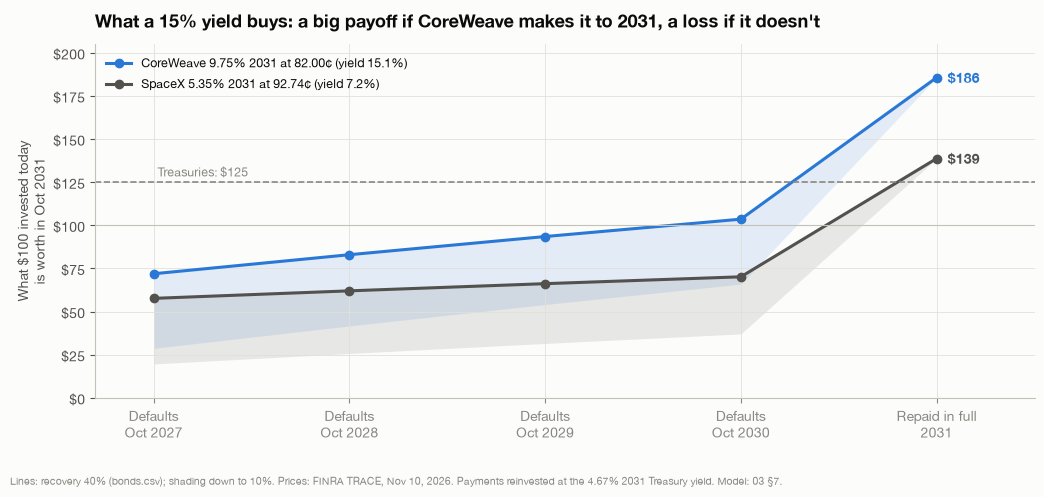

In [10]:
YRS = [NOW.year + d for d in DEFAULT_AT]
xs = list(range(len(YRS) + 1))
fig, ax = plt.subplots(figsize=(10.5, 4.8))
for bid, col, name in [('CRWV_9.75_2031', BOND, 'CoreWeave 9.75% 2031'), ('SPCX_5.350_2031', INK2, 'SpaceX 5.35% 2031')]:
    R0 = bonds.loc[bid, 'assumed_recovery']
    line = [wealth(flows(bid, d, R0)) for d in DEFAULT_AT] + [wealth(flows(bid))]
    low = [wealth(flows(bid, d, min(R_RANGE))) for d in DEFAULT_AT] + [wealth(flows(bid))]
    ax.fill_between(xs, low, line, color=col, alpha=0.12, lw=0)
    ax.plot(xs, line, color=col, lw=2.2, marker='o', label=f"{name} at {L.loc[bid, 'price']:.2f}¢ (yield {L.loc[bid, 'yield']:.1f}%)")
    ax.annotate(f'${line[-1]:.0f}', (xs[-1], line[-1]), xytext=(8, 0), textcoords='offset points', va='center', color=col, fontweight='bold')
ax.axhline(W_T, color=MUTED, ls='--', lw=1.2)
ax.text(0.02, W_T + 3, f'Treasuries: ${W_T:.0f}', color=MUTED, fontsize=9)
ax.axhline(100, color=AXIS, lw=0.8)
ax.set_xticks(xs, [f'Defaults\nOct {y}' for y in YRS] + ['Repaid in full\n2031'])
ax.set_xlim(-0.3, xs[-1] + 0.5); ax.set_ylim(0, 205)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f'${v:.0f}'))
ax.set_ylabel('What $100 invested today\nis worth in Oct 2031')
ax.legend(loc='upper left', fontsize=9)
ax.set_title('What a 15% yield buys: a big payoff if CoreWeave makes it to 2031, a loss if it doesn\'t', pad=12)
source_note(fig, f'Lines: recovery {bonds.loc[PAIR[0], "assumed_recovery"]:.0%} (bonds.csv); shading down to {min(R_RANGE):.0%}. '
                 f'Prices: FINRA TRACE, {NOW:%b %-d, %Y}. Payments reinvested at the {RF:.2%} 2031 Treasury yield. Model: 03 §7.')
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(CHARTS / '03_what_the_yield_buys.png', dpi=200, bbox_inches='tight')
plt.show()

**What this shows** (`charts/03_what_the_yield_buys.png` and the table above; Nov 10, 2026 prices):
- **$100 in Treasuries becomes ~$125 by Oct 2031.** That's the bar.
- **CoreWeave at ~15.1%: ~$186 if it pays in full, and well under $100 if it doesn't.** A default in Oct 2028 leaves ~$83 at 40% recovery, ~$62 at 25%, ~$42 at 10%. Even a default one year before maturity at 40% recovery loses to Treasuries. **The 15% only shows up if CoreWeave makes it to Oct 2031.**
- **So it's worth it if you think CoreWeave pays you back in full with better than ~40–60% odds** (about 40% at 40% recovery, about 50% at 25%, defaulting around 2028). That's the same bet as §2's ~60% five-year default odds, stated from the buyer's side.
- **SpaceX at ~7.2%: ~$139 if repaid, only ~$14 more than Treasuries.** A default leaves ~$40–70. **You need to be ~80–89% sure of being repaid** for the extra ~2.5 points a year to be worth it. The stock implies ~0% (06 §7), so on SpaceX's own equity the bet looks good. The risk a SpaceX buyer actually carries is the size of the loss if things go wrong, because new GPU lenders stand ahead of the notes (06 §6).

**Next:** what has to be true for CoreWeave to reach 2031, and for SpaceX to keep finding new money? That's 08 §3 (the GPU rental price) and 06 §5–6 (SpaceX's funding needs and its Starlink backstop). `research.ipynb` §6–7 puts these together for the post.

## Findings, by section

- **§1–3 · All prices imply far more defaults than history; compare within ratings.** (`03_implied_default_odds.png`)
  - Apple prices safer than an average AA.
  - Meta's long bonds are ~3× an average AA; the SPVs ~4× an A; SpaceX ~2× a BBB (~20–21% over 5 years).
  - CoreWeave is ~2.2–2.4× a B (~60%), above CCC history.
- **§4 · Recovery moves the levels, not the ranking.** CoreWeave stays near or above CCC history at any plausible recovery.
- **§5 · Since issue:** SpaceX +9.3 points, Meta 2056 +4.9, Alphabet 2056 +2.9. SPVs flat; Apple flat to safer.
- **§6 · Timing** (`03_default_timing.png`):
  - Meta is back-loaded (1% → 3.6% a year).
  - Alphabet has the same shape at a third of the level.
  - SpaceX is flat at ~3.5–4% a year from day one, explained in 06.
  - CoreWeave is ~13.5–15% a year with no view past 2032.
- **§7 · What the yield buys** (`03_what_the_yield_buys.png`). In dollars by Oct 2031 per $100: Treasuries ~$125.
  - CoreWeave ~$186 if repaid; any default before maturity loses even to Treasuries. Worth it above ~40–60% odds of full repayment.
  - SpaceX ~$139 if repaid; needs ~80–89% confidence.

**Handoff:** `data/implied_pd.csv` (5-year odds by bond, used by 05) and `data/forward_pd.csv` (forward rates, used by 06).

## Notes and caveats

- **These are upper bounds, not forecasts.** Even Apple's price implies many times its rating's historical default rate. That gap is the price of illiquidity and risk, not a forecast that Apple will default. That's why the useful comparison is **within a rating** (dot vs. gray tick), plus how far a bond sits from Apple's ratio to history.
- **CoreWeave's recovery is probably below 40%.** The unsecured notes rank behind ~$25B of secured debt (DDTLs, which are secured by GPUs and contracts). If the secured lenders take most of the collateral, unsecured holders get what's left. A lower R makes the implied odds *lower* (each default costs more, so fewer are needed to justify the spread). The sensitivity table shows that range. Even so, at 0% recovery the 5-year implied odds sit far above B+ history, which puts the market's view of CoreWeave closer to CCC than to its rating. Notebook 04 (GPU collateral) should firm up R.
- **CoreWeave's notes are rated B / B1, one notch below the issuer** (B+ / Ba3). FINRA's bond pages show the issue ratings (last rated Oct 20 2026, read Nov 11). That's the usual notching for unsecured notes behind a large secured stack. The history marker uses B (14.7% over 5 years, was 12.9% at B+). The price still implies ~4× that.
- **Beignet / Sopaipilla at 60% recovery.** The building plus Meta's residual value guarantee (RVG) sounds safe. But the RVG only pays if Meta ends the lease *and* other conditions are met, it's capped (~$28B for Hyperion, declining over time), and it isn't a guarantee of the notes. If Meta keeps paying rent, the notes are fine. If Meta walks *and* the RVG doesn't trigger, recovery depends on what a specialised data center is worth to someone else. 60% is a midpoint, not a fact.
- **Beignet and Sopaipilla amortize.** The 02 yield treats them as bullets, which understates their spreads. 07 §2 has the amortizing version (~250–265bp at a ~15-year average life). 07 §5 also shows the SPVs' premium over Meta can't plausibly be all default risk.
- **The history is global and issuer-weighted** (1981–2024, all sectors). It has few tech companies building data centers on borrowed money, so it's the prior, not a verdict.
- **Constant annual PD** in sections 2–5. Section 6 relaxes this with forward rates bootstrapped from each issuer's bonds, net of Apple.